# Preparation

In [1]:
#@title Import Libs
#@markdown All libraries import goes over here

import os
import glob
import time
import joblib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("TensorFlow version:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))
print("All libraries imported successfully.")

TensorFlow version: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
All libraries imported successfully.


In [2]:
#@title Import Datasets

USE_MY_DRIVE = True #@param {type:"boolean"}
#@markdown > If you decided to **USE_MY_DRIVE** make sure to first run the latest version of [**02_data_preparation.ipynb**](https://colab.research.google.com/drive/1mdcqA8y9RN-pgtv3hRnDm2ZsheJqQnSe?usp=drive_link) with save to drive on
SHARED_FOLDER_URL = 'https://drive.google.com/drive/folders/1oj1cqdfyh1ouXThXJbjgamLA6H5nX8nF'

data_dir = 'processed_data'
loaded_from_my_drive = False

if USE_MY_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_path = '/content/drive/MyDrive/DataScience-ProjectUAS/processed_data'
        if os.path.exists(f'{drive_path}/dataset_1_splits.pkl'):
            data_dir = drive_path
            loaded_from_my_drive = True
            print(f"Loaded from personal Google Drive: {data_dir}")
    except ImportError:
        pass

if not loaded_from_my_drive:
    os.makedirs(data_dir, exist_ok=True)
    if not glob.glob(f'{data_dir}/**/dataset_1_splits.pkl', recursive=True):
        print("Downloading splits from shared Google Drive folder...")
        subprocess.run(
            ['gdown', '--folder', SHARED_FOLDER_URL, '-O', data_dir, '--remaining-ok'],
            check=True
        )
    matched = glob.glob(f'{data_dir}/**/dataset_1_splits.pkl', recursive=True)
    data_dir = os.path.dirname(matched[0])
    print(f"Loaded from shared Drive fallback: {data_dir}")

dataset_1 = joblib.load(f'{data_dir}/dataset_1_splits.pkl')
dataset_2 = joblib.load(f'{data_dir}/dataset_2_splits.pkl')
dataset_3 = joblib.load(f'{data_dir}/dataset_3_splits.pkl')

print("All datasets ready for modeling.")

Mounted at /content/drive
Loaded from personal Google Drive: /content/drive/MyDrive/DataScience-ProjectUAS/processed_data
All datasets ready for modeling.


# Deep Learning Modeling

In [3]:
#@title Konfigurasi & Preprocessing Khusus Deep Learning

SEED = 42 #@param {type:"integer"}
DENSE_UNITS_1 = 128 #@param {type:"integer"}
DENSE_UNITS_2 = 64 #@param {type:"integer"}
DROPOUT_RATE = 0.3 #@param {type:"number"}
LEARNING_RATE = 0.001 #@param {type:"number"}
EPOCHS = 20 #@param {type:"integer"}
BATCH_SIZE_DS1 = 128 #@param {type:"integer"}
BATCH_SIZE_DS2 = 2048 #@param {type:"integer"}
BATCH_SIZE_DS3 = 64 #@param {type:"integer"}

np.random.seed(SEED)
tf.random.set_seed(SEED)

datasets_splits = {
    'Dataset 1': dataset_1,
    'Dataset 2': dataset_2,
    'Dataset 3': dataset_3
}

dl_datasets = {}

for nama, split in datasets_splits.items():
    X_train_dl = np.asarray(split['X_train'], dtype=np.float32)
    y_train_dl = np.asarray(split['y_train'], dtype=np.float32).reshape(-1)
    X_val_dl = np.asarray(split['X_val'], dtype=np.float32)
    y_val_dl = np.asarray(split['y_val'], dtype=np.float32).reshape(-1)

    dl_datasets[nama] = {
        'X_train': X_train_dl,
        'y_train': y_train_dl,
        'X_val': X_val_dl,
        'y_val': y_val_dl
    }
    print(f"{nama} -> input_shape: ({X_train_dl.shape[1]},) | train: {X_train_dl.shape[0]} | val: {X_val_dl.shape[0]}")

print("\nModel: Multilayer Perceptron (MLP) Regressor")
print("Jumlah dataset:", len(dl_datasets))

Dataset 1 -> input_shape: (116,) | train: 18152 | val: 3890
Dataset 2 -> input_shape: (27,) | train: 699838 | val: 149965
Dataset 3 -> input_shape: (28,) | train: 7000 | val: 1500

Model: Multilayer Perceptron (MLP) Regressor
Jumlah dataset: 3


In [4]:
#@title Desain Arsitektur MLP & Model Summary

def build_mlp_regressor(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,), name='input_layer'),
        layers.Dense(DENSE_UNITS_1, name='dense_1'),
        layers.BatchNormalization(name='batch_normalization_1'),
        layers.ReLU(name='relu_1'),
        layers.Dropout(DROPOUT_RATE, name='dropout_1'),
        layers.Dense(DENSE_UNITS_2, name='dense_2'),
        layers.BatchNormalization(name='batch_normalization_2'),
        layers.ReLU(name='relu_2'),
        layers.Dropout(DROPOUT_RATE, name='dropout_2'),
        layers.Dense(1, activation='linear', name='output_layer')
    ], name=f'MLP_Regressor_{input_dim}D')
    return model

for nama, split in dl_datasets.items():
    input_dim = split['X_train'].shape[1]
    print(f"\n=== Model Summary: {nama} ===")
    temp_model = build_mlp_regressor(input_dim)
    temp_model.summary()


=== Model Summary: Dataset 1 ===


Model: "MLP_Regressor_116D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │        14,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,065 (94.00 KB)

 Trainable params: 23,681 (92.50 KB)

 Non-trainable params: 384 (1.50 KB)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,801 (50.00 KB)

 Trainable params: 12,417 (48.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [5]:
#@title Training Awal Multilayer Perceptron

dl_models = {}
dl_histories = {}
training_times = {}

batch_sizes = {
    'Dataset 1': BATCH_SIZE_DS1,
    'Dataset 2': BATCH_SIZE_DS2,
    'Dataset 3': BATCH_SIZE_DS3
}

for nama, split in dl_datasets.items():
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    input_dim = split['X_train'].shape[1]
    batch_size = batch_sizes[nama]

    model = build_mlp_regressor(input_dim)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='mse',
        metrics=['mae']
    )

    print(f"\n--- Training {nama} (batch_size={batch_size}, epochs={EPOCHS}) ---")
    start_time = time.time()

    history = model.fit(
        split['X_train'],
        split['y_train'],
        validation_data=(split['X_val'], split['y_val']),
        epochs=EPOCHS,
        batch_size=batch_size,
        verbose=1
    )

    elapsed = time.time() - start_time

    dl_models[nama] = model
    dl_histories[nama] = history.history
    training_times[nama] = round(elapsed, 2)

    print(f"{nama}: Training selesai ({elapsed:.2f} detik)")

print("\nSeluruh model Deep Learning berhasil dilatih.")


--- Training Dataset 1 (batch_size=128, epochs=20) ---
Epoch 1/20
142/142 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - loss: 12808687616.0000 - mae: 76263.0859 - val_loss: 13662365696.0000 - val_mae: 78541.9609
Epoch 2/20
142/142 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 12806238208.0000 - mae: 76256.6172 - val_loss: 13659862016.0000 - val_mae: 78535.7031
Epoch 3/20
142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 12802468864.0000 - mae: 76247.1797 - val_loss: 13654730752.0000 - val_mae: 78523.7578
Epoch 4/20
142/142 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 12796911616.0000 - mae: 76233.0234 - val_loss: 13646629888.0000 - val_mae: 78504.2031
Epoch 5/20
142/142 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 12789230592.0000 - mae: 76213.1328 - val_loss: 13636546560.0000 - val_mae: 78479.0234
Epoch 6/20
142/142 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 12779171840.0000 - mae: 76186.4375 - val_loss: 13624518656.0000 - val_mae: 78449.1328
Epoch 7/20
142/142 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1276695

In [6]:
#@title Evaluasi Training & Validation

dl_results = []

for nama, split in dl_datasets.items():
    model = dl_models[nama]
    batch_size = batch_sizes[nama]

    y_train_pred = model.predict(split['X_train'], batch_size=batch_size, verbose=0).reshape(-1)
    y_val_pred = model.predict(split['X_val'], batch_size=batch_size, verbose=0).reshape(-1)

    train_rmse = np.sqrt(
        mean_squared_error(
            split['y_train'],
            y_train_pred
        )
    )

    val_rmse = np.sqrt(
        mean_squared_error(
            split['y_val'],
            y_val_pred
        )
    )

    val_mae = mean_absolute_error(
        split['y_val'],
        y_val_pred
    )

    val_r2 = r2_score(
        split['y_val'],
        y_val_pred
    )

    dl_results.append({
        'Dataset': nama,
        'Input_Dim': split['X_train'].shape[1],
        'Train_RMSE': train_rmse,
        'Val_RMSE': val_rmse,
        'Val_MAE': val_mae,
        'Val_R2': val_r2,
        'Train_Time_Sec': training_times[nama]
    })

dl_metrics_df = pd.DataFrame(dl_results)

display(dl_metrics_df.round(4))

,Dataset,Input_Dim,Train_RMSE,Val_RMSE,Val_MAE,Val_R2,Train_Time_Sec
0,Dataset 1,116,111627.8067,115295.6003,77506.1094,-0.7737,21.42
1,Dataset 2,27,0.5077,0.5077,0.4052,0.9103,40.58
2,Dataset 3,28,6.7169,7.0172,5.6860,0.9662,16.75


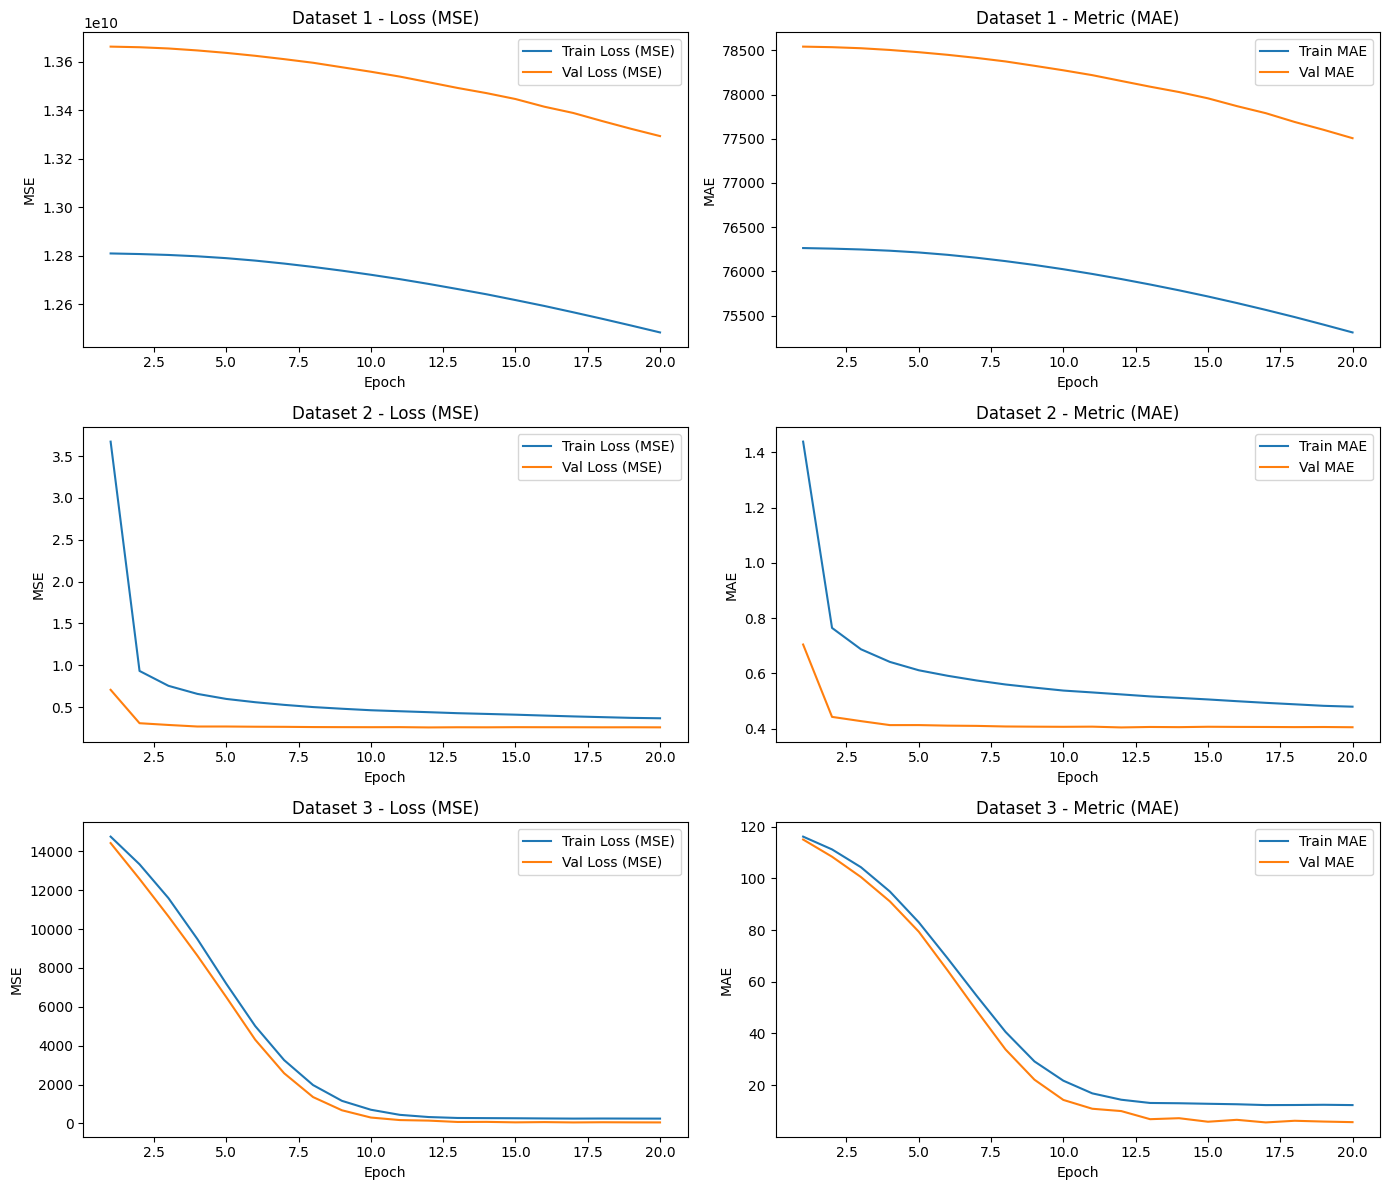

In [7]:
#@title Visualisasi Kurva Loss & Metric

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for idx, (nama, hist) in enumerate(dl_histories.items()):
    epochs_range = range(1, len(hist['loss']) + 1)

    axes[idx, 0].plot(epochs_range, hist['loss'], label='Train Loss (MSE)')
    axes[idx, 0].plot(epochs_range, hist['val_loss'], label='Val Loss (MSE)')
    axes[idx, 0].set_title(f'{nama} - Loss (MSE)')
    axes[idx, 0].set_xlabel('Epoch')
    axes[idx, 0].set_ylabel('MSE')
    axes[idx, 0].legend()

    axes[idx, 1].plot(epochs_range, hist['mae'], label='Train MAE')
    axes[idx, 1].plot(epochs_range, hist['val_mae'], label='Val MAE')
    axes[idx, 1].set_title(f'{nama} - Metric (MAE)')
    axes[idx, 1].set_xlabel('Epoch')
    axes[idx, 1].set_ylabel('MAE')
    axes[idx, 1].legend()

plt.tight_layout()
plt.show()

# Simpan Model & Hasil Evaluasi

In [8]:
#@title Simpan Model & Hasil Evaluasi

model_dir = 'models'
plot_dir = 'eda_plots'

if os.path.exists('/content/drive/MyDrive/DataScience-ProjectUAS'):
    model_dir = '/content/drive/MyDrive/DataScience-ProjectUAS/models'
    plot_dir = '/content/drive/MyDrive/DataScience-ProjectUAS/eda_plots'

os.makedirs(model_dir, exist_ok=True)
os.makedirs(plot_dir, exist_ok=True)

dl_metrics_df.to_csv(
    f'{model_dir}/dl_mlp_initial_val_metrics.csv',
    index=False
)

fig.savefig(f'{plot_dir}/dl_1_initial_training_history.png', dpi=150)

for nama, model in dl_models.items():
    filename = nama.lower().replace(' ', '_')
    model.save(f'{model_dir}/{filename}_mlp_initial.keras')

print("Model dan hasil evaluasi berhasil disimpan.")

Model dan hasil evaluasi berhasil disimpan.
